In [2]:
%pip install scikit-learn

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   -------- ------------------------------- 1.8/8.4 MB 8.8 MB/s eta 0:00:01
   --------------- ------------------------ 3.1/8.4 MB 7.5 MB/s eta 0:00:01
   -------------------- ------------------- 4.2/8.4 MB 7.0 MB/s eta 0:00:01
   ---------------------- ----------------- 4.7/8.4 MB 6.2 MB/s eta 0:00:01
   ----------------------- ---------------- 5.0/8.4 MB 5.3 MB/s eta 0:00:01
   ------------------------- -------------- 5.2/8.4 MB 4.5 MB/s eta 0:00:01
   -------------------------- ------------- 5.5/8.4 MB 4.1 MB/s eta 0:00:01
   ---------------------------- ----------- 6.0/8.4 MB 3.5 MB/s eta 0:00:01
   ------------------------------- -------- 6.6/8.4 MB 3.4 MB/s eta 0:00:01
   ----------------------------------- ---- 7.3/8.4 MB 3.4 MB/s eta 0:00:01
   ---------------------------------------- 8.4/8.4 MB 3.5 MB/s  0:00:02
   -----------------


[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("All libraries imported successfully!")
print("Scikit-learn version:", sklearn.__version__)

All libraries imported successfully!
Scikit-learn version: 1.9.1


In [6]:
df = pd.read_csv("../AI-ML-Internship/Day 9/laptop_data_cleaned.csv")

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())

Dataset shape: (1243, 11)

Column names:
['brand', 'type', 'screen_size_inch', 'screen_resolution', 'cpu', 'ram_gb', 'storage', 'gpu', 'os', 'weight_kg', 'price_inr']


,brand,type,screen_size_inch,screen_resolution,cpu,ram_gb,storage,gpu,os,weight_kg,price_inr
0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37,71379
1,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34,47896
2,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8,256GB SSD,Intel HD Graphics 620,No OS,1.86,30636
3,Apple,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16,512GB SSD,AMD Radeon Pro 455,macOS,1.83,135195
4,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37,96096


In [7]:
print("All columns in the dataset:")

for col in df.columns:
    print(col)

print("\nDataset information:")
df.info()

print("\nMissing values in each column:")
print(df.isnull().sum())

All columns in the dataset:
brand
type
screen_size_inch
screen_resolution
cpu
ram_gb
storage
gpu
os
weight_kg
price_inr

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1243 entries, 0 to 1242
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   brand              1243 non-null   str    
 1   type               1243 non-null   str    
 2   screen_size_inch   1243 non-null   float64
 3   screen_resolution  1243 non-null   str    
 4   cpu                1243 non-null   str    
 5   ram_gb             1243 non-null   int64  
 6   storage            1243 non-null   str    
 7   gpu                1243 non-null   str    
 8   os                 1243 non-null   str    
 9   weight_kg          1243 non-null   float64
 10  price_inr          1243 non-null   int64  
dtypes: float64(2), int64(2), str(7)
memory usage: 106.9 KB

Missing values in each column:
brand                0
type                 0


In [8]:
print("Column names:")
print(df.columns.tolist())

Column names:
['brand', 'type', 'screen_size_inch', 'screen_resolution', 'cpu', 'ram_gb', 'storage', 'gpu', 'os', 'weight_kg', 'price_inr']


In [9]:
# Remove rows where the target price is missing
df = df.dropna(subset=["price_inr"]).copy()

# Input features (X)
X = df.drop(columns=["price_inr"])

# Target variable (y)
y = df["price_inr"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())
display(y.head())

Features shape: (1243, 10)
Target shape: (1243,)


,brand,type,screen_size_inch,screen_resolution,cpu,ram_gb,storage,gpu,os,weight_kg
0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37
1,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34
2,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8,256GB SSD,Intel HD Graphics 620,No OS,1.86
3,Apple,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16,512GB SSD,AMD Radeon Pro 455,macOS,1.83
4,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37


0     71379
1     47896
2     30636
3    135195
4     96096
Name: price_inr, dtype: int64

In [10]:
# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (994, 10)
Testing features: (249, 10)
Training target: (994,)
Testing target: (249,)


In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Identify numeric and categorical columns
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Numeric features: ['screen_size_inch', 'ram_gb', 'weight_kg']
Categorical features: ['brand', 'type', 'screen_resolution', 'cpu', 'storage', 'gpu', 'os']


C:\Users\sunid\AppData\Local\Temp\ipykernel_15800\261847481.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


In [12]:
# Preprocess numeric features
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocess categorical features
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing steps
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [13]:
# Create the complete machine learning pipeline
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

# Train the model
model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [14]:
# Predict laptop prices for the test dataset
y_pred = model.predict(X_test)

# Compare actual and predicted prices
results = pd.DataFrame({
    "Actual Price (INR)": y_test.values,
    "Predicted Price (INR)": y_pred.round(2)
})

display(results.head(10))

,Actual Price (INR),Predicted Price (INR)
0,38889,39291.26
1,21792,16530.12
2,30316,41596.76
3,99580,71617.63
4,77789,79858.54
5,83064,66213.78
6,25060,24848.85
7,45102,44093.44
8,39907,45180.04
9,31382,43535.95


In [15]:
# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): ₹{mae:,.2f}")
print(f"Root Mean Squared Error (RMSE): ₹{rmse:,.2f}")
print(f"R² Score: {r2:.4f}")

Mean Absolute Error (MAE): ₹13,389.00
Root Mean Squared Error (RMSE): ₹22,628.06
R² Score: 0.5905


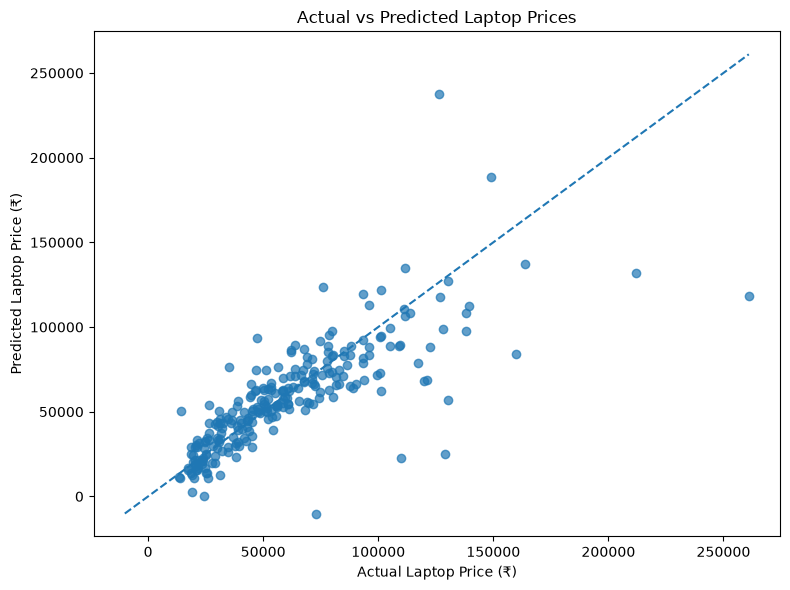

In [16]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.7)

# Ideal predictions lie on this diagonal
min_price = min(y_test.min(), y_pred.min())
max_price = max(y_test.max(), y_pred.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--"
)

plt.xlabel("Actual Laptop Price (₹)")
plt.ylabel("Predicted Laptop Price (₹)")
plt.title("Actual vs Predicted Laptop Prices")
plt.tight_layout()
plt.show()

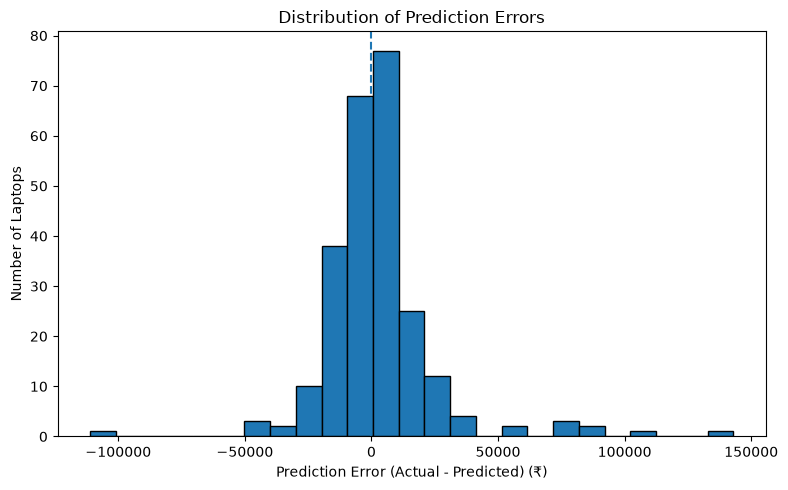

In [17]:
errors = y_test - y_pred

plt.figure(figsize=(8, 5))
plt.hist(errors, bins=25, edgecolor="black")
plt.axvline(0, linestyle="--")

plt.xlabel("Prediction Error (Actual - Predicted) (₹)")
plt.ylabel("Number of Laptops")
plt.title("Distribution of Prediction Errors")
plt.tight_layout()
plt.show()

In [18]:
# Example laptop specifications
new_laptop = pd.DataFrame([{
    "brand": "HP",
    "type": "Notebook",
    "screen_size_inch": 15.6,
    "screen_resolution": "Full HD 1920x1080",
    "cpu": "Intel Core i5 2.5GHz",
    "ram_gb": 8,
    "storage": "512GB SSD",
    "gpu": "Intel HD Graphics 620",
    "os": "Windows 10",
    "weight_kg": 2.0
}])

# Predict the price
predicted_price = model.predict(new_laptop)[0]

print(f"Predicted laptop price: ₹{predicted_price:,.2f}")

Predicted laptop price: ₹74,971.77


In [19]:
import joblib

joblib.dump(model, "laptop_price_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [20]:
import joblib

loaded_model = joblib.load("laptop_price_model.pkl")

test_prediction = loaded_model.predict(new_laptop)[0]

print(f"Loaded model prediction: ₹{test_prediction:,.2f}")

Loaded model prediction: ₹74,971.77
